<a href="https://colab.research.google.com/github/dgaida/wpf_cps_th_public/blob/main/assets/exercises/week_07/04_varianz_position_kubisch_monte_carlo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Warum wächst die Varianz der Position kubisch ($t^3$) und nicht quadratisch ($t^2$)?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dgaida/wpf_cps_th_public/blob/main/assets/exercises/week_07/04_varianz_position_kubisch_monte_carlo.ipynb)

Beim Entwurf von Zustandsschätzern (wie dem **Kalman-Filter**) oder bei der Koppelnavigation (**Dead Reckoning**) mittels Inertialsensoren (IMU / Beschleunigungssensoren) stößt man häufig auf eine scheinbar kontraintuitive Frage:

> **Intuitive, aber falsche Vermutung:**  
> Da der Weg aus der Beschleunigung durch zweifache Integration hervorgeht ($p(t) = \frac{1}{2} a t^2$), vermutet man intuitiv oft, dass die Varianz des Positionsfehlers mit der Zeit quadratisch wächst:  
> $$\operatorname{Var}(p(t)) \propto t^2 \quad \text{??? (FALSCH!)}$$

Tatsächlich wächst die Varianz des Positionsfehlers infolge von weißem Beschleunigungsrauschen **kubisch mit der Zeit**:
$$\operatorname{Var}(p(t)) \propto t^3$$

In diesem Notebook klären wir:
1. **Warum die naive Intuition $t^2$ falsch ist** und wann welcher Exponent auftritt.
2. **Die exakte kontinuierliche mathematische Herleitung** über stochastische Faltungsintegrale.
3. **Die exakte zeitdiskrete mathematische Herleitung** über das lineare Zustandsraummodell.
4. **Den empirischen Beweis mittels einer Monte-Carlo-Simulation** mit $M = 20.000$ Simulationsläufen.
5. **Eine Regressionsanalyse im Log-Log-Diagramm**, die den Skalierungsexponenten $3.0$ zweifelsfrei bestätigt.

## 1. Die Intuition und der Trugschluss: Warum nicht $t^2$?

### Woher kommt die Vermutung $t^2$?
In der klassischen deterministischen Mechanik gilt für eine konstante Beschleunigung $a$:
$$p(t) = p_0 + v_0 \cdot t + \frac{1}{2} a \cdot t^2$$

Betrachtet man verschiedene Fehlertypen, muss man strikt unterscheiden:

| Fehlertyp in der Sensorik | Mathematische Modellierung | Fehler in $p(t)$ | Varianz $\operatorname{Var}(p(t))$ |
| :--- | :--- | :--- | :--- |
| **Anfangsgeschwindigkeitsfehler** | $v_0 \sim \mathcal{N}(0, \sigma_{v_0}^2)$, konstant über Zeit | $\Delta p(t) = \Delta v_0 \cdot t$ | $\propto t^2$ |
| **Konstanter Beschleunigungsbias (Offset)** | $b_a \sim \mathcal{N}(0, \sigma_b^2)$, konstant über Zeit | $\Delta p(t) = \frac{1}{2} b_a \cdot t^2$ | $\propto t^4$ |
| **Weißes Beschleunigungsrauschen (Sensorrauschen)** | $w_a(t)$ unkorreliert zu jedem Zeitpunkt | $\Delta p(t) = \int_0^t (t - \tau) w_a(\tau) d\tau$ | **$\propto t^3$** |

### Der fundamentale Unterschied: Korreliert vs. Unkorreliert
- Ein **fester Fehler** (Bias) wirkt über die gesamte Zeitspanne kohärent in die gleiche Richtung. Der Positionsfehler wächst linear mit $t$ (bei Geschwindigkeitsbias $\rightarrow \Delta p \propto t$, Varianz $\propto t^2$) bzw. quadratisch mit $t^2$ (bei Beschleunigungsbias $\rightarrow \Delta p \propto t^2$, Varianz $\propto t^4$).
- **Weißes Rauschen** hingegen ändert in jedem infinitesimalen Zeitschritt seine Richtung (Zufallsvariablen sind unkorreliert). 
- Nach dem zentralen Grenzwertsatz und den Gesetzen der Brownschen Bewegung wächst die Varianz der Summe unabhängiger Zufallsvariablen mit der Anzahl der Schritte.
- Da für die Position **zweimal** integriert wird, akkumuliert sich die Geschwindigkeitsvarianz linear ($\propto t$), und die Integration der integrierten Geschwindigkeit führt zu einem weiteren Zeitfaktor, wodurch sich insgesamt **$t^3$** ergibt!

## 2. Mathematische Herleitung im Kontinuierlichen

Betrachten wir ein 1D-System mit idealer Anfangsruhe ($p(0) = 0$, $v(0) = 0$). Das System wird durch die stochastische Differentialgleichung angetrieben:
$$\dot{p}(t) = v(t)$$
$$\dot{v}(t) = w_a(t)$$

Hierbei ist $w_a(t)$ weißes Gaußsches Rauschen mit Mittelwert Null und Autokorrelationsfunktion:
$$\mathbb{E}[w_a(t)] = 0, \quad \mathbb{E}[w_a(t_1) w_a(t_2)] = q \cdot \delta(t_1 - t_2)$$
wobei $q$ die spektrale Leistungsdichte (PSD) des Beschleunigungsrauschens ist und $\delta(\cdot)$ die Dirac-Delta-Distribution.

### Schritt 1: Geschwindigkeit $v(t)$
Die Geschwindigkeit ist das einfache Integral über das Rauschen:
$$v(t) = \int_0^t w_a(\tau) \, d\tau$$

Die Varianz der Geschwindigkeit ist:
$$\operatorname{Var}(v(t)) = \mathbb{E}[v(t)^2] = \mathbb{E}\left[ \left( \int_0^t w_a(\tau) \, d\tau \right)^2 \right] = \int_0^t \int_0^t \mathbb{E}[w_a(\tau_1) w_a(\tau_2)] \, d\tau_1 d\tau_2$$
Da $\mathbb{E}[w_a(\tau_1) w_a(\tau_2)] = q \cdot \delta(\tau_1 - \tau_2)$:
$$\operatorname{Var}(v(t)) = \int_0^t q \, d\tau_1 = q \cdot t$$
Die Varianz der Geschwindigkeit wächst also **linear** mit $t$ (Standard-Wiener-Prozess / Random Walk).

### Schritt 2: Position $p(t)$
Die Position ist das Integral der Geschwindigkeit:
$$p(t) = \int_0^t v(s) \, ds = \int_0^t \left( \int_0^s w_a(\tau) \, d\tau \right) ds$$

Mit der **Cauchy-Formel für wiederholte Integration** (bzw. Vertauschung der Integrationsreihenfolge nach Fubini):
$$\int_0^t ds \int_0^s d\tau \, w_a(\tau) = \int_0^t d\tau \, w_a(\tau) \int_\tau^t ds = \int_0^t (t - \tau) w_a(\tau) \, d\tau$$

Anschaulich: Ein Beschleunigungsimpuls zum Zeitpunkt $\tau$ erzeugt eine Geschwindigkeitsstufe, die über die verbleibende Zeitdauer $(t - \tau)$ auf die Position einwirkt!

### Schritt 3: Varianz der Position $\operatorname{Var}(p(t))$
Da $\mathbb{E}[p(t)] = 0$, berechnet sich die Varianz als Erwartungswert des Quadrats:
$$\operatorname{Var}(p(t)) = \mathbb{E}[p(t)^2] = \mathbb{E}\left[ \left( \int_0^t (t - \tau) w_a(\tau) \, d\tau \right)^2 \right]$$

Wir schreiben das Quadrat als Doppelintegral:
$$\operatorname{Var}(p(t)) = \int_0^t d\tau_1 \int_0^t d\tau_2 \, (t - \tau_1)(t - \tau_2) \, \mathbb{E}[w_a(\tau_1) w_a(\tau_2)]$$

Wir setzen wieder $\mathbb{E}[w_a(\tau_1) w_a(\tau_2)] = q \cdot \delta(\tau_1 - \tau_2)$ ein:
$$\operatorname{Var}(p(t)) = \int_0^t (t - \tau)^2 \cdot q \, d\tau$$

Dieses Integral lässt sich elementar lösen (Substitution $u = t - \tau$, $du = -d\tau$):
$$\operatorname{Var}(p(t)) = q \int_0^t u^2 \, du = q \left[ \frac{u^3}{3} \right]_0^t = \mathbf{\frac{1}{3} q \cdot t^3}$$

$$\bbox[10px,border:2px solid #2e7d32,background-color:#e8f5e9]{\operatorname{Var}(p(t)) = \frac{1}{3} q \cdot t^3 \quad \Longrightarrow \quad \sigma_p(t) = \sqrt{\frac{q}{3}} \cdot t^{1.5}}$$

Damit ist exakt bewiesen: **Die Varianz wächst mit $t^3$, und die Standardabweichung mit $t^{3/2} = t^{1.5}$!**

## 3. Mathematische Herleitung im Zeitdiskreten (Zustandsraummodell)

In Rechnern und diskreten Kalman-Filtern wird die Zeit in Intervalle $\Delta t$ diskretisiert: $t_k = k \cdot \Delta t$.

Aus dem kinematischen Modell (wie in Notebook `03_lineares_system_1d_simulation.ipynb`):
$$v_{k+1} = v_k + a_{\mathrm{meas}, k} \cdot \Delta t$$
$$p_{k+1} = p_k + v_k \cdot \Delta t + \frac{1}{2} a_{\mathrm{meas}, k} \cdot \Delta t^2$$

Nehmen wir an, das Objekt startet in Ruhe ($p_0 = 0, v_0 = 0$) und die tatsächliche Beschleunigung ist 0, sodass die Messung reines weißes Rauschen ist:
$$a_{\mathrm{meas}, k} = w_{a, k} \quad \text{mit} \quad w_{a, k} \sim \mathcal{N}(0, \sigma_a^2) \quad \text{i.i.d.}$$

### Explizite Summenformel für Zeitschritt $k$
Durch sukzessives Einsetzen erhält man:
- $v_k = \Delta t \sum_{j=0}^{k-1} w_{a, j}$
- Jeder Rauschwert $w_{a, i}$ zum Schritt $i \in \{0, \dots, k-1\}$ wirkt auf die Endposition $p_k$ über:
  - den direkten Term: $\frac{1}{2} \Delta t^2 w_{a, i}$
  - und die akkumulierte Geschwindigkeit über alle $(k - 1 - i)$ Folgeschritte: $(k - 1 - i) \Delta t^2 w_{a, i}$

Zusammengefasst hat $w_{a, i}$ im Zustand $p_k$ den Einflusskoeffizienten:
$$c_{k, i} = \left( (k - 1 - i) + \frac{1}{2} \right) \Delta t^2 = \left( k - i - \frac{1}{2} \right) \Delta t^2$$

Somit lautet die Position zum Schritt $k$:
$$p_k = \Delta t^2 \sum_{i=0}^{k-1} \left( k - i - \frac{1}{2} \right) w_{a, i}$$

### Berechnung der diskreten Varianz
Da alle $w_{a, i}$ unabhängig mit Varianz $\sigma_a^2$ sind, gilt für die Varianz der Summe:
$$\operatorname{Var}(p_k) = \Delta t^4 \cdot \sigma_a^2 \cdot \sum_{i=0}^{k-1} \left( k - i - \frac{1}{2} \right)^2$$

Wir substituieren den Index $m = k - 1 - i$. Wenn $i$ von $0$ bis $k-1$ läuft, läuft $m$ von $k-1$ bis $0$:
$$\sum_{m=0}^{k-1} \left( m + \frac{1}{2} \right)^2 = \sum_{m=0}^{k-1} \left( m^2 + m + \frac{1}{4} \right)$$

Unter Verwendung der bekannten Potenzsummen:
- $\sum_{m=0}^{k-1} m^2 = \frac{(k-1)k(2k-1)}{6} = \frac{2k^3 - 3k^2 + k}{6}$
- $\sum_{m=0}^{k-1} m = \frac{(k-1)k}{2} = \frac{3k^2 - 3k}{6}$
- $\sum_{m=0}^{k-1} \frac{1}{4} = \frac{k}{4} = \frac{1.5k}{6}$

Addieren wir alle drei Terme:
$$\sum_{m=0}^{k-1} \left( m + \frac{1}{2} \right)^2 = \frac{2k^3 - 3k^2 + k + 3k^2 - 3k + 1.5k}{6} = \frac{2k^3 - 0.5k}{6} = \frac{4k^3 - k}{12}$$

Eingesetzt in die Varianzformel:
$$\operatorname{Var}(p_k) = \sigma_a^2 \cdot \Delta t^4 \cdot \frac{4k^3 - k}{12} = \frac{1}{3} \sigma_a^2 \Delta t \cdot (k \Delta t)^3 - \frac{1}{12} \sigma_a^2 \Delta t^3 \cdot (k \Delta t)$$

Mit der Gesamtzeit $t = k \Delta t$ und dem Rauschparameter $q = \sigma_a^2 \Delta t$:
$$\bbox[10px,border:2px solid #1565c0,background-color:#e3f2fd]{\operatorname{Var}(p_k) = \frac{1}{3} \sigma_a^2 \Delta t \cdot t^3 - \frac{1}{12} \sigma_a^2 \Delta t^3 \cdot t = \frac{1}{3} q t^3 \cdot \left( 1 - \frac{1}{4 k^2} \right)}$$

Für $k \gg 1$ ist der Term $\frac{1}{4k^2}$ vernachlässigbar klein und die zeitdiskrete Formel geht exakt in die kontinuierliche Formel $\frac{1}{3} q t^3$ über!

## 4. Monte-Carlo-Simulation

Wir verifizieren diese theoretischen Ergebnisse nun empirisch über eine **Monte-Carlo-Simulation** mit $M = 20.000$ unabhängigen Durchläufen.

### Simulationsparameter:
- Zeitschrittweite: $\Delta t = 0.1\,\text{s}$
- Anzahl der Zeitschritte: $N = 100$ ($t_{\mathrm{end}} = 10.0\,\text{s}$)
- Anzahl der Monte-Carlo-Realisierungen: $M = 20.000$
- Rauschstandardabweichung: $\sigma_a = 0.5\,\text{m/s}^2$

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Reproduzierbarkeit festlegen
np.random.seed(42)

# Parameter
dt = 0.1             # Zeitschrittweite [s]
num_steps = 100      # Anzahl Zeitschritte (t_end = 10 s)
num_runs = 20000     # Anzahl Monte-Carlo-Realisierungen
sigma_a = 0.5        # Standardabweichung des Beschleunigungsrauschens [m/s^2]

time_grid = np.linspace(0, num_steps * dt, num_steps + 1)

print(f"Starte Monte-Carlo-Simulation mit {num_runs:,} Pfaden über {num_steps} Zeitschritte...")

# Vektorisierte Generierung des Rauschens: Matrix der Dimension (num_runs, num_steps)
w_a = np.random.normal(0.0, sigma_a, size=(num_runs, num_steps))

# Zustände initialisieren (Position und Geschwindigkeit)
p_paths = np.zeros((num_runs, num_steps + 1))
v_paths = np.zeros((num_runs, num_steps + 1))

# Zeitdiskrete Integration (Dead Reckoning)
for k in range(num_steps):
    p_paths[:, k + 1] = p_paths[:, k] + v_paths[:, k] * dt + 0.5 * w_a[:, k] * dt**2
    v_paths[:, k + 1] = v_paths[:, k] + w_a[:, k] * dt

# Empirische Kennwerte berechnen
mean_p = np.mean(p_paths, axis=0)
var_p_empirical = np.var(p_paths, axis=0)
std_p_empirical = np.std(p_paths, axis=0)

# Theoretische Werte
k_grid = np.arange(num_steps + 1)
var_p_exact_discrete = (sigma_a**2) * (dt**4) * (4.0 * k_grid**3 - k_grid) / 12.0
var_p_asymptotic_t3 = (1.0 / 3.0) * (sigma_a**2 * dt) * (time_grid**3)

# Hypothetische quadratische Kurve t^2 (skaliert, sodass sie am Endpunkt mit t^3 übereinstimmt)
var_p_hypothetical_t2 = var_p_asymptotic_t3[-1] * (time_grid / time_grid[-1])**2

print("✓ Monte-Carlo-Simulation erfolgreich abgeschlossen!")
print(f"Endzeit t = {time_grid[-1]:.1f} s:")
print(f"  Empirische Varianz:               {var_p_empirical[-1]:.4f} m^2")
print(f"  Exakte zeitdiskrete Varianz:       {var_p_exact_discrete[-1]:.4f} m^2")
print(f"  Asymptotische Theorie (1/3 q t^3): {var_p_asymptotic_t3[-1]:.4f} m^2")
rel_diff = abs(var_p_empirical[-1] - var_p_exact_discrete[-1]) / var_p_exact_discrete[-1] * 100
print(f"  Relative Abweichung Simulation vs. Theorie: {rel_diff:.3f}%")

Starte Monte-Carlo-Simulation mit 20,000 Pfaden über 100 Zeitschritte...


✓ Monte-Carlo-Simulation erfolgreich abgeschlossen!
Endzeit t = 10.0 s:
  Empirische Varianz:               8.3398 m^2
  Exakte zeitdiskrete Varianz:       8.3331 m^2
  Asymptotische Theorie (1/3 q t^3): 8.3333 m^2
  Relative Abweichung Simulation vs. Theorie: 0.081%


## 5. Visualisierung: Trajektorien und Konfidenzbänder

Im folgenden Diagramm sehen wir links eine Auswahl einzelner Trajektorien mit den theoretischen $\pm 1\sigma$-, $\pm 2\sigma$- und $\pm 3\sigma$-Grenzen. Rechts vergleichen wir den empirischen Mittelwert mit dem theoretischen Erwartungswert ($0$).

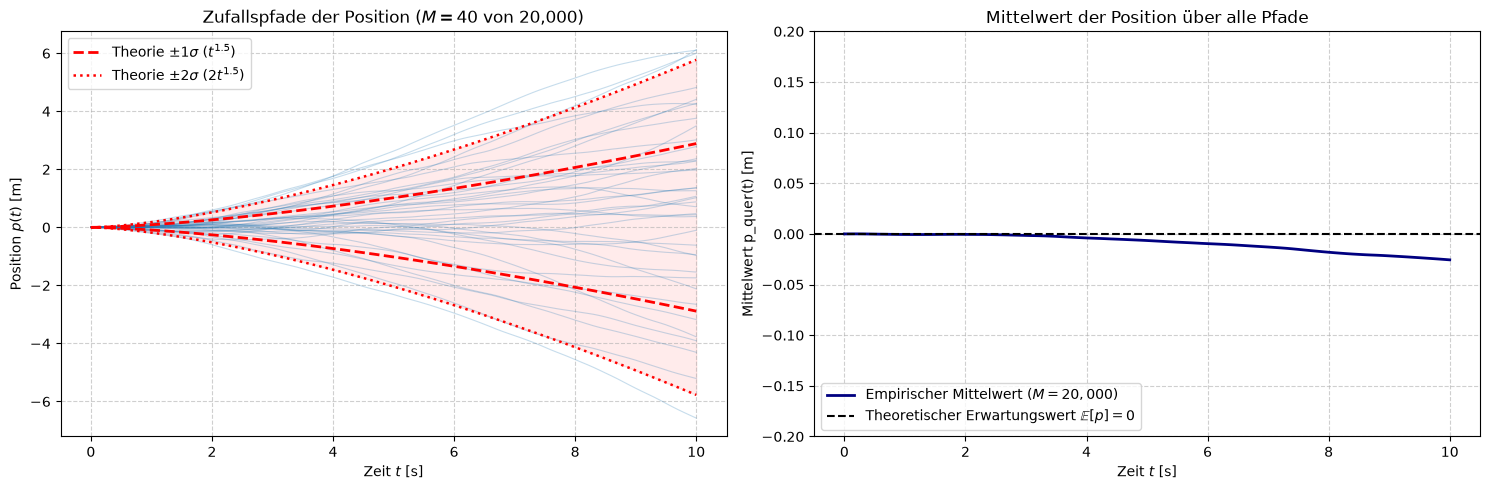

In [2]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Ausgewählte Pfade und Konfidenzbänder
num_sample_paths = 40
for i in range(num_sample_paths):
    ax1.plot(time_grid, p_paths[i, :], color='tab:blue', alpha=0.25, linewidth=0.8)

# Theoretische Sigma-Grenzen
std_exact = np.sqrt(var_p_exact_discrete)
ax1.plot(time_grid, std_exact, 'r--', linewidth=2, label=r'Theorie $\pm 1\sigma$ ($t^{1.5}$)')
ax1.plot(time_grid, -std_exact, 'r--', linewidth=2)
ax1.plot(time_grid, 2 * std_exact, 'r:', linewidth=1.8, label=r'Theorie $\pm 2\sigma$ ($2 t^{1.5}$)')
ax1.plot(time_grid, -2 * std_exact, 'r:', linewidth=1.8)
ax1.fill_between(time_grid, -2 * std_exact, 2 * std_exact, color='red', alpha=0.08)

ax1.set_title(f"Zufallspfade der Position ($M={num_sample_paths}$ von {num_runs:,})")
ax1.set_xlabel("Zeit $t$ [s]")
ax1.set_ylabel("Position $p(t)$ [m]")
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(loc='upper left')

# Plot 2: Empirischer Mittelwert (Erwartungstreue)
ax2.plot(time_grid, mean_p, 'navy', linewidth=2, label=f'Empirischer Mittelwert ($M={num_runs:,}$)')
ax2.axhline(0.0, color='black', linestyle='--', linewidth=1.5, label=r'Theoretischer Erwartungswert $\mathbb{E}[p]=0$')
ax2.set_title("Mittelwert der Position über alle Pfade")
ax2.set_xlabel("Zeit $t$ [s]")
ax2.set_ylabel("Mittelwert p_quer(t) [m]")
ax2.set_ylim([-0.2, 0.2])
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend(loc='lower left')

plt.tight_layout()
plt.show()

## 6. Gegenüberstellung der Varianzen: $t^3$ vs. $t^2$

Hier vergleichen wir die empirisch ermittelte Varianz $\operatorname{Var}(p_k)$ direkt mit:
1. Der **exakten analytischen zeitdiskreten Varianz**: $\frac{4k^3 - k}{12} \Delta t^4 \sigma_a^2$
2. Der **asymptotischen kubischen Kurve**: $\frac{1}{3} q t^3$
3. Einer **hypothetischen quadratischen Kurve**: $\propto t^2$ (normalisiert auf den gleichen Endwert)

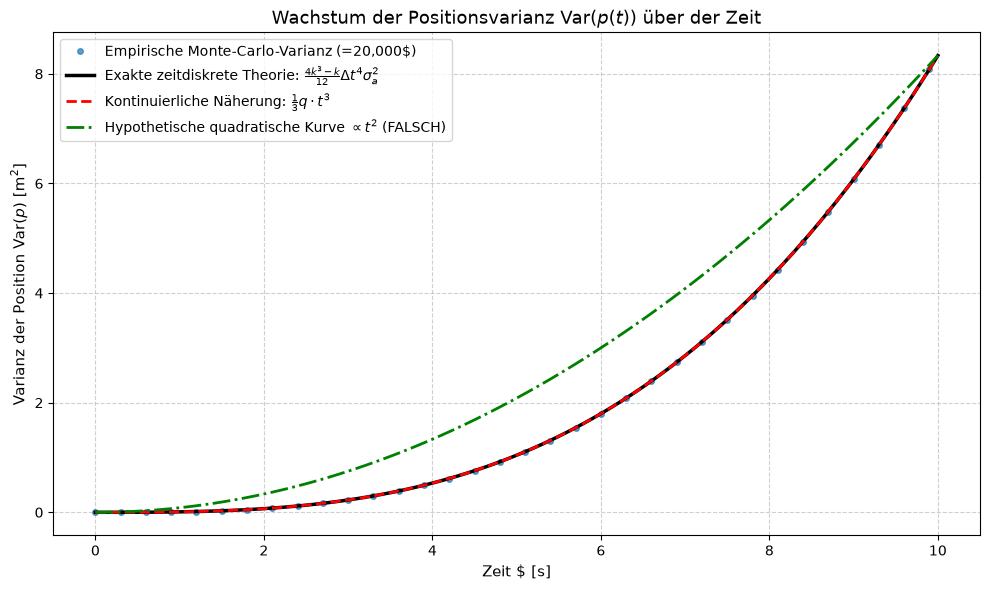

In [3]:
fig, ax = plt.subplots(figsize=(10, 6))

# Empirische Varianz
ax.plot(time_grid, var_p_empirical, 'o', color='tab:blue', markersize=4, alpha=0.7, 
        markevery=3, label=f'Empirische Monte-Carlo-Varianz (={num_runs:,}$)')

# Exakte zeitdiskrete Theorie
ax.plot(time_grid, var_p_exact_discrete, 'k-', linewidth=2.5, 
        label=r'Exakte zeitdiskrete Theorie: $\frac{4k^3 - k}{12} \Delta t^4 \sigma_a^2$')

# Asymptotische Theorie t^3
ax.plot(time_grid, var_p_asymptotic_t3, 'r--', linewidth=2, 
        label=r'Kontinuierliche Näherung: $\frac{1}{3} q \cdot t^3$')

# Hypothetische quadratische Kurve t^2
ax.plot(time_grid, var_p_hypothetical_t2, 'g-.', linewidth=2, 
        label=r'Hypothetische quadratische Kurve $\propto t^2$ (FALSCH)')

ax.set_title(r"Wachstum der Positionsvarianz $\operatorname{Var}(p(t))$ über der Zeit", fontsize=13)
ax.set_xlabel("Zeit $ [s]", fontsize=11)
ax.set_ylabel(r"Varianz der Position $\operatorname{Var}(p)$ [m$^2$]", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(fontsize=10, loc='upper left')

plt.tight_layout()
plt.show()


## 7. Der numerische Beweis: Steigung im Log-Log-Diagramm

Gilt für eine Funktion ein Potenzgesetz $y(t) = c \cdot t^m$, so gilt im doppelt-logarithmischen Maßstab:
$$\log(y(t)) = \log(c) + m \cdot \log(t)$$

Die **Steigung $m$** der Geraden im Log-Log-Plot entspricht somit exakt dem **Potenzexponenten**:
- Bei $t^2$ wäre die Steigung $m = 2.0$.
- Bei $t^3$ ist die Steigung $m = 3.0$.

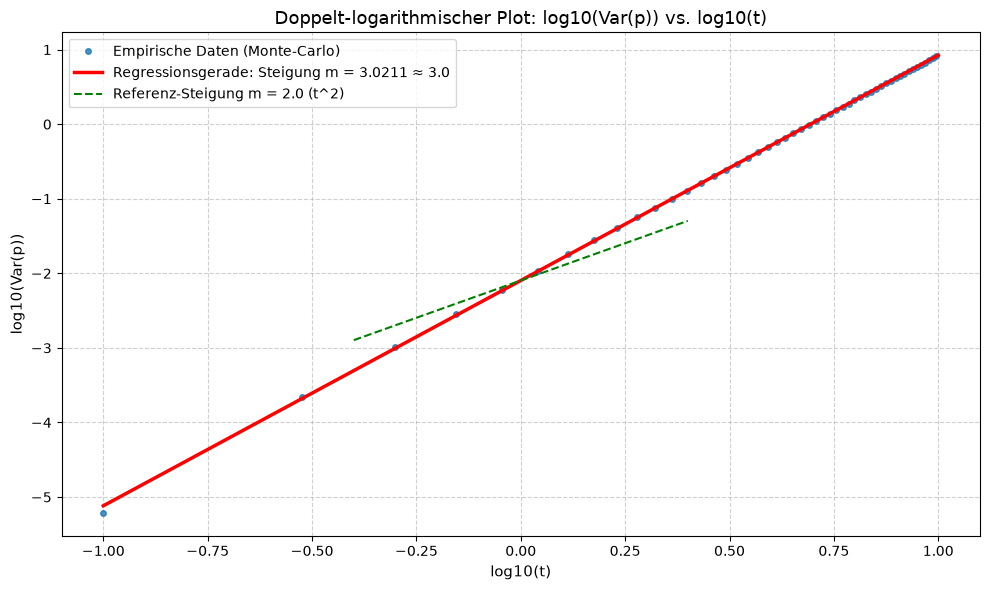

ERGEBNIS DER REGRESSIONSANALYSE:
Ermittelter Exponent (Steigung m): 3.0211
Theoretischer Exponent:            3.0000
Abweichung:                        0.0211


In [4]:
# Wir schließen t=0 aus, da log(0) nicht definiert ist
valid_idx = slice(1, None)
log_t = np.log10(time_grid[valid_idx])
log_var_emp = np.log10(var_p_empirical[valid_idx])

# Lineare Regression zur Bestimmung des Exponenten m
slope, intercept = np.polyfit(log_t, log_var_emp, deg=1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(log_t, log_var_emp, "o", color="tab:blue", markersize=4, alpha=0.8, markevery=2,
        label="Empirische Daten (Monte-Carlo)")
ax.plot(log_t, slope * log_t + intercept, "r-", linewidth=2.5,
        label=f"Regressionsgerade: Steigung m = {slope:.4f} ≈ 3.0")

# Referenz-Steigungslinien
mid_x = (log_t[0] + log_t[-1]) / 2.0
mid_y = slope * mid_x + intercept
delta_x = 0.4
ax.plot([mid_x - delta_x, mid_x + delta_x], 
        [mid_y - 2.0 * delta_x, mid_y + 2.0 * delta_x], 
        "g--", linewidth=1.5, label="Referenz-Steigung m = 2.0 (t^2)")

ax.set_title("Doppelt-logarithmischer Plot: log10(Var(p)) vs. log10(t)", fontsize=13)
ax.set_xlabel("log10(t)", fontsize=11)
ax.set_ylabel("log10(Var(p))", fontsize=11)
ax.grid(True, which="both", linestyle="--", alpha=0.6)
ax.legend(fontsize=10, loc="upper left")

plt.tight_layout()
plt.show()

print("=" * 60)
print(f"ERGEBNIS DER REGRESSIONSANALYSE:")
print(f"Ermittelter Exponent (Steigung m): {slope:.4f}")
print(f"Theoretischer Exponent:            3.0000")
print(f"Abweichung:                        {abs(slope - 3.0):.4f}")
print("=" * 60)


## 8. Zusammenfassung & Kernbotschaften

1. **Doppelintegration von weißem Rauschen**:  
   Weißes Rauschen in der Beschleunigung $w_a(t)$ erzeugt in der Geschwindigkeit einen Random Walk mit Varianz $\propto t$. Die erneute Integration zur Position liefert nicht $t^2$, sondern wegen des zeitlich wachsenden Hebels $(t - \tau)$ ein **kubisches Anwachsen der Varianz**:
   $$\operatorname{Var}(p(t)) = \frac{1}{3} q \cdot t^3$$

2. **Standardabweichung / Unsicherheitsintervall**:  
   Das $\sigma$-Konfidenzintervall der Position wächst mit:
   $$\sigma_p(t) \propto t^{3/2} = t^{1.5}$$
   Nach $10\,\text{s}$ ist die Unsicherheit nicht etwa $10$-mal so groß wie nach $1\,\text{s}$ (wie bei $t^1$), sondern um das $10^{1.5} \approx 31.6$-Fache gewachsen!

3. **Bedeutung für die Robotik und CPS**:  
   - Reine Koppelnavigation (Dead Reckoning) auf Basis von IMU-Beschleunigungswerten ist über längere Zeiträume ohne externe Stützung unbrauchbar, da die Positionsunsicherheit extrem schnell ($t^3$) explodiert.
   - **Lösung**: Der **Kalman-Filter** fusioniert das Modell der Doppelintegration mit absoluten Positionsmessungen (z. B. GPS, LiDAR oder Kamera), wodurch die Drift gestoppt und die Varianz auf ein stationäres Niveau begrenzt wird.